In [1]:
import numpy as np
import pandas as pd
import cv2
from matplotlib import pyplot as plt
from numpy.linalg import inv
import os

from colormath.color_conversions import convert_color
from colormath.color_objects import LabColor, XYZColor
from colormath.color_diff import delta_e_cie2000

import skimage
from skimage.color import rgb2lab, lab2rgb

from scipy.interpolate import BSpline, make_interp_spline

from scipy.optimize import minimize
from scipy.optimize import dual_annealing
from scipy.optimize import least_squares
from scipy.optimize import basinhopping

from numpy.random import random
from numpy.random import rand

from tensorflow import keras
from tensorflow.keras import layers
import tensorflow as tf

import time

In [2]:
nbi_weights = []
nbi_weights.append(np.load('weight_nbi0.npy'))
nbi_weights.append(np.load('weight_nbi1.npy'))
nbi_weights.append(np.load('weight_nbi2.npy'))
nbi_weights.append(np.load('weight_nbi3.npy'))
nbi_weights.append(np.load('weight_nbi4.npy'))
nbi_weights.append(np.load('weight_nbi5.npy'))

In [22]:
md_path = 'nbi'
model = keras.models.load_model(md_path)

model.load_weights('cap3.hdf5')

nbi_weights = model.get_weights() 

In [23]:
def sToneCurve(frame):
    look_up_table = np.zeros((256,1), dtype = 'uint8')
    for i in range(256):
        look_up_table[i][0] = 255 * (np.sin(np.pi * (i/255 - 1/2)) + 1) / 2
    return cv2.LUT(frame, look_up_table)

def to_nbi(img):
    
    img_shape = img.shape
    
    tar_img = img.reshape(-1,3) / 255
    
    tar_img = np.dot(tar_img, nbi_weights[0]) + nbi_weights[1]
    tar_img = np.dot(tar_img, nbi_weights[2]) + nbi_weights[3]
    tar_img = np.dot(tar_img, nbi_weights[4]) + nbi_weights[5]

    tar_img = tar_img * 255 * 1.5

    tar_img = tar_img.reshape(img_shape)
    
    tar_img[tar_img>255] = 255
    tar_img[tar_img<0] = 0
    
    tar_img = tar_img.astype('uint8')
    
    tar_img = sToneCurve(tar_img)
    
    return tar_img

In [24]:
# img = cv2.imread('img_cap3.jpg')
img = cv2.imread('cap1.bmp')

img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

t0 = time.time()

nbi = to_nbi(img)

print(time.time() - t0)

0.010393857955932617


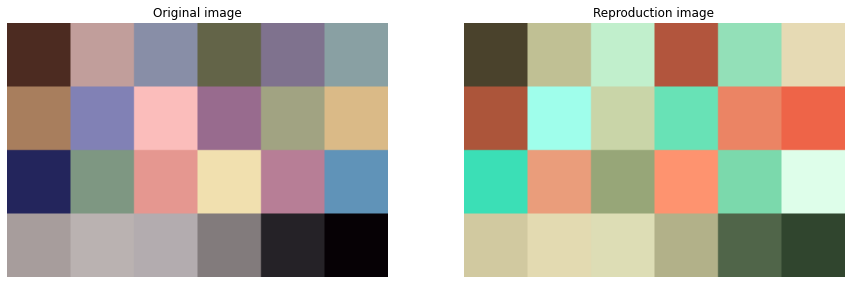

In [25]:
plt.figure(figsize=(15, 6))

plt.subplot(1,2,1)
plt.imshow(img)
plt.title('Original image')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(nbi)
plt.title('Reproduction image')
plt.axis('off')

plt.show()

# By LUT - Dict, for loop transfer

In [6]:
# Create table

table_dict = dict()

for r in range(256):    
    for g in range(256):
        
        b_img = np.zeros((256,3), dtype = 'uint8')
        
        for b in range(256):
            
            b_img[b,:] = np.array([r,g,b], dtype = 'uint8')
            
        to_b_img = to_nbi(b_img)

        for b in range(256):
            
            from_v = r + (g<<8) + (b<<16)
            table_dict[from_v] = to_b_img[b,:]

print('table length:', len(table_dict))

table length: 16777216


In [9]:
# transfer

t0 = time.time()

# reshape as nx3, and to int
temp_img = img.reshape(-1, 3).astype(int)

# transfer to table key
img_keys = temp_img[:,0] + np.left_shift(temp_img[:,1], 8) + np.left_shift(temp_img[:,2], 16)

# table mapping
img_values = [table_dict[key] for key in img_keys]

# reconstruct to rgb image
img_trans = np.array(img_values, dtype = 'uint8')
img_trans = img_trans.reshape(img.shape)

print(time.time() - t0)

0.6378524303436279


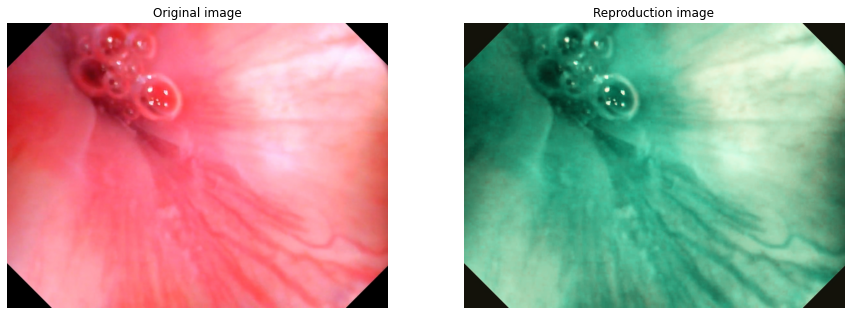

In [10]:
plt.figure(figsize=(15, 6))

plt.subplot(1,2,1)
plt.imshow(img)
plt.title('Original image')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(img_trans)
plt.title('Reproduction image')
plt.axis('off')

plt.show()

# By LUT - Integer array indexing

In [11]:
# Create table

table_index = np.zeros(256*256*256, dtype = 'int')

for r in range(256):    
    for g in range(256):
        
        b_img = np.zeros((256,3), dtype = 'uint8')
        
        for b in range(256):
            
            b_img[b,:] = np.array([r,g,b], dtype = 'uint8')
            
        to_b_img = to_nbi(b_img)
        to_b_img = sToneCurve(to_b_img)
        
        to_b_img = to_b_img.astype('int')
        to_b_img_keys = to_b_img[:,0] + np.left_shift(to_b_img[:,1], 8) + np.left_shift(to_b_img[:,2], 16)
        
        for b in range(256):
            
            from_v = r + (g<<8) + (b<<16)
            table_index[from_v] = to_b_img_keys[b]
            
print('table_index shape', table_index.shape)

table_index shape (16777216,)


In [37]:
# transfer

t0 = time.time()

# reshape as nx3, and to int
temp_img = img.reshape(-1, 3).astype(int)

# transfer to table key
img_keys = temp_img[:,0] + np.left_shift(temp_img[:,1], 8) + np.left_shift(temp_img[:,2], 16)

# table mapping
img_values = table_index[img_keys]

# reconstruct to rgb image
img_r = img_values.astype('uint8')
img_g = np.right_shift(img_values, 8).astype('uint8')
img_b = np.right_shift(img_values, 16).astype('uint8')

img_trans = np.column_stack((img_r, img_g, img_b))

img_trans = img_trans.reshape(img.shape)

print(time.time() - t0)

0.02733302116394043


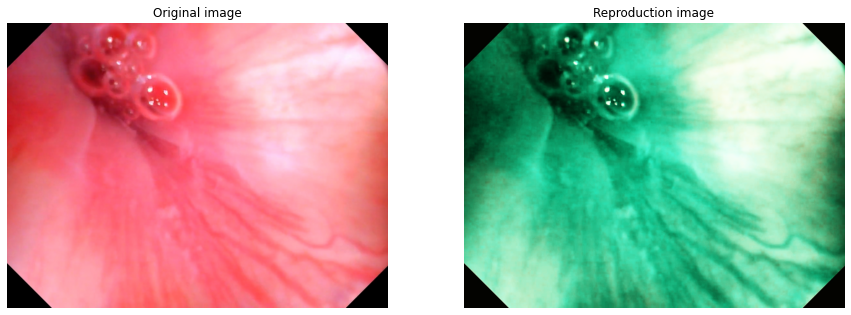

In [13]:
plt.figure(figsize=(15, 6))

plt.subplot(1,2,1)
plt.imshow(img)
plt.title('Original image')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(img_trans)
plt.title('Reproduction image')
plt.axis('off')

plt.show()

# By LUT - Function mapping

In [15]:
table_func = np.zeros((256,256,256,3), dtype = 'uint8')

for r in range(256):    
    for g in range(256):
        
        b_img = np.zeros((256,3), dtype = 'uint8')
        
        for b in range(256):
            
            b_img[b,:] = np.array([r,g,b], dtype = 'uint8')
            
        to_b_img = to_nbi(b_img)

        for b in range(256):
            
            table_func[r,g,b,:] = to_b_img[b,:]

In [16]:
def func_trans(key):
    return table_func[key[0], key[1], key[2]]

In [18]:
t0 = time.time()

img_keys = img.reshape(-1, 3).astype(int)

img_trans = np.array(list(map(func_trans, img_keys)))

img_trans = img_trans.reshape(img.shape)

print(time.time() - t0)

1.0361781120300293


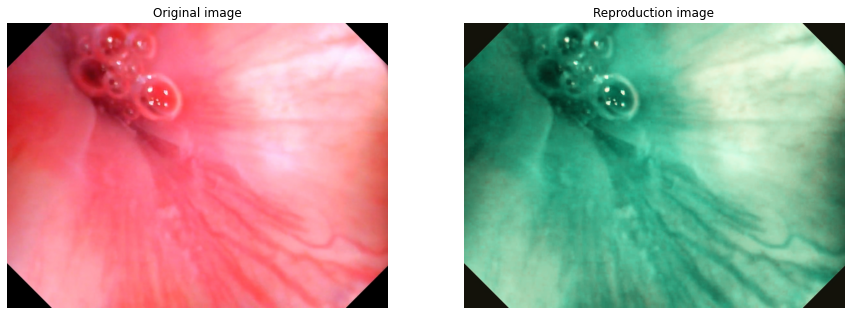

In [19]:
plt.figure(figsize=(15, 6))

plt.subplot(1,2,1)
plt.imshow(img)
plt.title('Original image')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(img_trans)
plt.title('Reproduction image')
plt.axis('off')

plt.show()

# By LUT - itertools mapping

In [20]:
# undone

In [55]:
import itertools
img_trans = np.zeros(img_keys.shape, dtype = 'uint8')

for i, j in itertools.combinations(img_keys.shape[0], img_keys.shape[1]):
    img_trans[i, j] = table_func[j, j, j]

TypeError: 'int' object is not iterable

# Dump table

In [7]:
import numpy as np
import pandas as pd
import cv2
from matplotlib import pyplot as plt
from numpy.linalg import inv
import os

from colormath.color_conversions import convert_color
from colormath.color_objects import LabColor, XYZColor
from colormath.color_diff import delta_e_cie2000

import skimage
from skimage.color import rgb2lab, lab2rgb

from scipy.interpolate import BSpline, make_interp_spline

from scipy.optimize import minimize
from scipy.optimize import dual_annealing
from scipy.optimize import least_squares
from scipy.optimize import basinhopping

from numpy.random import random
from numpy.random import rand

from tensorflow import keras
from tensorflow.keras import layers
import tensorflow as tf

import time

In [8]:
md_file = 'wli1.hdf5'
gain = 1.0
is_s_curve = False

dump_table_file = 'wli1.npy'

In [9]:
md_path = 'nbi'
model = keras.models.load_model(md_path)

model.load_weights(md_file)

nbi_weights = model.get_weights() 

In [10]:
def sToneCurve(frame):
    look_up_table = np.zeros((256,1), dtype = 'uint8')
    for i in range(256):
        look_up_table[i][0] = 255 * (np.sin(np.pi * (i/255 - 1/2)) + 1) / 2
    return cv2.LUT(frame, look_up_table)

def to_nbi(img):
    
    img_shape = img.shape
    
    tar_img = img.reshape(-1,3) / 255
    
    tar_img = np.dot(tar_img, nbi_weights[0]) + nbi_weights[1]
    tar_img = np.dot(tar_img, nbi_weights[2]) + nbi_weights[3]
    tar_img = np.dot(tar_img, nbi_weights[4]) + nbi_weights[5]

    tar_img = tar_img * 255 * gain

    tar_img = tar_img.reshape(img_shape)
    
    tar_img[tar_img>255] = 255
    tar_img[tar_img<0] = 0
    
    tar_img = tar_img.astype('uint8')
    
    if is_s_curve:
        tar_img = sToneCurve(tar_img)
    
    return tar_img

In [11]:
table_index = np.zeros(256*256*256, dtype = 'int')

for r in range(256):    
    for g in range(256):
        
        b_img = np.zeros((256,3), dtype = 'uint8')
        
        for b in range(256):
            
            b_img[b,:] = np.array([r,g,b], dtype = 'uint8')
            
        to_b_img = to_nbi(b_img)
        to_b_img = sToneCurve(to_b_img)
        
        to_b_img = to_b_img.astype('int')
        to_b_img_keys = to_b_img[:,0] + np.left_shift(to_b_img[:,1], 8) + np.left_shift(to_b_img[:,2], 16)
        
        for b in range(256):
            
            from_v = r + (g<<8) + (b<<16)
            table_index[from_v] = to_b_img_keys[b]
            
print('table_index shape', table_index.shape)

table_index shape (16777216,)


In [12]:
np.save(dump_table_file, table_index)

In [3]:
for w in nbi_weights:
    print(w.shape)

(3, 24)
(24,)
(24, 24)
(24,)
(24, 3)
(3,)


In [10]:
np.savetxt(r'C:\Users\Tony\Desktop\111\w06.txt', nbi_weights[5])